# Pure Premium und Modellzusammenführung

In diesem Notebook werden die finalen Frequency- und Severity-Modelle
zusammengeführt, um für jede Police die erwartete jährliche Schadenbelastung
als Pure Premium zu schätzen.

Die Bewertung erfolgt zunächst auf dem gemeinsamen Holdout-Testdatensatz.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


# Project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


# Paths
CURATED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_curated.pq"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_train_test_split.pq"
)

FREQUENCY_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_holdout_v2.joblib"
)

SEVERITY_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "severity_gamma_spline_scaled_holdout_v2.joblib"
)


# Load data
df = pd.read_parquet(CURATED_PATH)
split_df = pd.read_parquet(SPLIT_PATH)

df["IDpol"] = df["IDpol"].astype("int64")
split_df["IDpol"] = split_df["IDpol"].astype("int64")

df = df.merge(
    split_df,
    on="IDpol",
    how="left",
    validate="one_to_one",
)


# Load evaluated model artifacts
frequency_model = joblib.load(
    FREQUENCY_MODEL_PATH
)

severity_model = joblib.load(
    SEVERITY_MODEL_PATH
)


# Common holdout set
test_df = (
    df.loc[df["split"] == "test"]
    .copy()
)


print("=== Pure Premium Setup Check ===")
print(f"Curated rows:       {len(df):,}")
print(f"Holdout policies:   {len(test_df):,}")
print(f"Missing split:      {df['split'].isna().sum():,}")

print("\n=== Model Artifacts ===")
print(f"Frequency model:    {FREQUENCY_MODEL_PATH.exists()}")
print(f"Severity model:     {SEVERITY_MODEL_PATH.exists()}")

print("\n=== Holdout Integrity ===")
print(f"Unique IDpol:       {test_df['IDpol'].nunique():,}")
print(f"Duplicate IDpol:    {test_df['IDpol'].duplicated().sum():,}")
print(f"Total Exposure:     {test_df['Exposure'].sum():,.2f}")
print(f"Actual Claims:      {test_df['ClaimNb'].sum():,.0f}")

=== Pure Premium Setup Check ===
Curated rows:       678,013
Holdout policies:   135,603
Missing split:      0

=== Model Artifacts ===
Frequency model:    True
Severity model:     True

=== Holdout Integrity ===
Unique IDpol:       135,603
Duplicate IDpol:    0
Total Exposure:     71,583.60
Actual Claims:      7,236


## Zusammenführung von Frequency und Severity

Die beiden evaluierten Modellartefakte werden auf dem gemeinsamen
Holdout-Datensatz angewendet.

Die erwartete jährliche Schadenbelastung je Police wird als **Pure Premium**
berechnet:

$$
\text{Predicted Pure Premium}
=
\text{Predicted Frequency}
\times
\text{Predicted Severity}
$$

Unter Berücksichtigung der jeweiligen Exposure ergeben sich zusätzlich:

$$
\text{Expected Claim Count}
=
\text{Predicted Frequency}
\times
\text{Exposure}
$$

$$
\text{Expected Claim Amount}
=
\text{Predicted Pure Premium}
\times
\text{Exposure}
$$

In [2]:
# Model input features
frequency_features = list(
    frequency_model.feature_names_in_
)

severity_features = list(
    severity_model.feature_names_in_
)

print("Frequency features:")
print(frequency_features)

print("\nSeverity features:")
print(severity_features)

print(
    "\nSame feature set:",
    frequency_features == severity_features,
)


# Predictions
test_df["predicted_frequency"] = (
    frequency_model.predict(
        test_df[frequency_features]
    )
)

test_df["predicted_severity"] = (
    severity_model.predict(
        test_df[severity_features]
    )
)


# Pure Premium
test_df["predicted_pure_premium"] = (
    test_df["predicted_frequency"]
    * test_df["predicted_severity"]
)


# Exposure-correct expectations
test_df["expected_claim_count"] = (
    test_df["predicted_frequency"]
    * test_df["Exposure"]
)

test_df["expected_claim_amount"] = (
    test_df["predicted_pure_premium"]
    * test_df["Exposure"]
)


print("\n=== Prediction Setup ===")
print(f"Policies:                {len(test_df):,}")
print(
    f"Frequency NaN:           "
    f"{test_df['predicted_frequency'].isna().sum():,}"
)
print(
    f"Severity NaN:            "
    f"{test_df['predicted_severity'].isna().sum():,}"
)
print(
    f"Pure Premium NaN:        "
    f"{test_df['predicted_pure_premium'].isna().sum():,}"
)

print(
    f"Non-positive Frequency:  "
    f"{(test_df['predicted_frequency'] <= 0).sum():,}"
)
print(
    f"Non-positive Severity:   "
    f"{(test_df['predicted_severity'] <= 0).sum():,}"
)
print(
    f"Non-positive Pure Prem.: "
    f"{(test_df['predicted_pure_premium'] <= 0).sum():,}"
)

Frequency features:
['VehPower', 'VehBrand', 'VehGas', 'Region', 'driver_age_group', 'vehicle_age_group', 'bonus_malus_segment', 'DrivAge', 'VehAge', 'BonusMalus', 'log_density']

Severity features:
['VehPower', 'VehBrand', 'VehGas', 'Region', 'DrivAge', 'VehAge', 'BonusMalus', 'log_density']

Same feature set: False

=== Prediction Setup ===
Policies:                135,603
Frequency NaN:           0
Severity NaN:            0
Pure Premium NaN:        0
Non-positive Frequency:  0
Non-positive Severity:   0
Non-positive Pure Prem.: 0


## Lorenz-Kurve und Gini der Pure Premium

Abschließend wird geprüft, wie gut die kombinierte Pure-Premium-Prognose
Policen nach ihrer tatsächlichen Schadenbelastung sortiert.

Da für einen Teil der Schadenpolicen keine beobachtete Schadenhöhe verfügbar
ist, erfolgt diese Analyse ausschließlich auf der Teilmenge mit bekannten
Schadenbeträgen. Die Ergebnisse sind daher als diagnostische
Risikorangfolge und nicht als unverzerrte Vollportfolio-Kennzahl zu
interpretieren.

Zusätzlich wird geprüft, ob die Severity-Komponente gegenüber einer
reinen Frequency-basierten Sortierung zusätzlichen Ranking-Nutzen liefert.

In [16]:
def loss_lorenz_gini(
    ranking_score,
    actual_claim_amount,
    exposure,
):
    evaluation = pd.DataFrame({
        "ranking_score": np.asarray(
            ranking_score
        ),
        "actual_claim_amount": np.asarray(
            actual_claim_amount
        ),
        "exposure": np.asarray(
            exposure
        ),
    })

    evaluation = (
        evaluation
        .sort_values(
            "ranking_score",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    cumulative_exposure = np.concatenate([
        [0.0],
        (
            evaluation["exposure"].cumsum()
            / evaluation["exposure"].sum()
        ).to_numpy(),
    ])

    cumulative_claim_amount = np.concatenate([
        [0.0],
        (
            evaluation["actual_claim_amount"].cumsum()
            / evaluation["actual_claim_amount"].sum()
        ).to_numpy(),
    ])

    lorenz_auc = np.trapezoid(
        cumulative_claim_amount,
        cumulative_exposure,
    )

    gini = 1 - 2 * lorenz_auc

    return (
        cumulative_exposure,
        cumulative_claim_amount,
        gini,
    )


pure_premium_gini_eval = (
    test_df.loc[
        complete_amount_mask
    ]
    .copy()
)


(
    frequency_loss_lorenz_x,
    frequency_loss_lorenz_y,
    frequency_loss_gini,
) = loss_lorenz_gini(
    pure_premium_gini_eval[
        "predicted_frequency"
    ],
    pure_premium_gini_eval[
        "total_claim_amount"
    ],
    pure_premium_gini_eval[
        "Exposure"
    ],
)


(
    pure_premium_lorenz_x,
    pure_premium_lorenz_y,
    pure_premium_gini,
) = loss_lorenz_gini(
    pure_premium_gini_eval[
        "predicted_pure_premium"
    ],
    pure_premium_gini_eval[
        "total_claim_amount"
    ],
    pure_premium_gini_eval[
        "Exposure"
    ],
)


pure_premium_gini_comparison = pd.DataFrame({
    "ranking": [
        "Frequency-only",
        "Pure Premium v2",
    ],
    "gini": [
        frequency_loss_gini,
        pure_premium_gini,
    ],
})

display(
    pure_premium_gini_comparison
)


print(
    "=== Pure Premium Gini Comparison ==="
)

print(
    f"Evaluation policies:       "
    f"{len(pure_premium_gini_eval):,}"
)

print(
    f"Frequency-only loss Gini:  "
    f"{frequency_loss_gini:.4f}"
)

print(
    f"Pure Premium v2 Gini:      "
    f"{pure_premium_gini:.4f}"
)

print(
    f"Severity contribution:     "
    f"{pure_premium_gini - frequency_loss_gini:+.4f}"
)

,ranking,gini
0,Frequency-only,0.237192
1,Pure Premium v2,0.235758


=== Pure Premium Gini Comparison ===
Evaluation policies:       133,790
Frequency-only loss Gini:  0.2372
Pure Premium v2 Gini:      0.2358
Severity contribution:     -0.0014


### Ergebnis

Auf der Teilmenge mit bekannten Schadenbeträgen erreicht die reine
Frequency-basierte Risikosortierung einen Gini-Koeffizienten von **0,2372**.

Die kombinierte Pure-Premium-Prognose erreicht **0,2358**. Die zusätzliche
Severity-Komponente verbessert das Risk Ranking damit nicht und reduziert
den Gini geringfügig um **0,0014**.

Der Unterschied ist sehr klein, bestätigt jedoch die zuvor beobachtete
begrenzte Ranking-Fähigkeit des Severity-Modells. Die Pure-Premium-
Komponente bleibt für die Schätzung erwarteter Schadenkosten relevant,
liefert gegenüber Frequency allein jedoch keinen zusätzlichen
Ranking-Vorteil.

Aufgrund fehlender Schadenbeträge für einen Teil der Schadenpolicen ist
diese Auswertung als diagnostische Analyse der beobachtbaren Teilmenge
zu interpretieren.

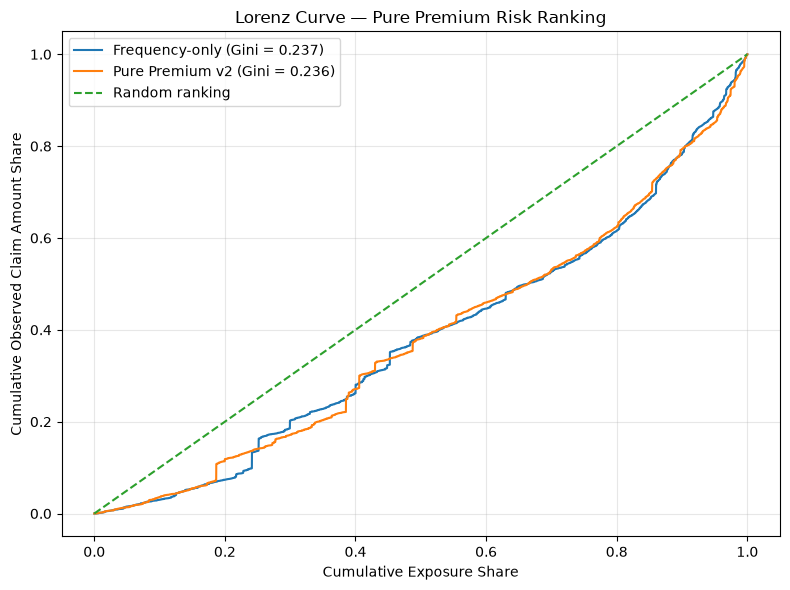

In [17]:
plt.figure(figsize=(8, 6))

plt.plot(
    frequency_loss_lorenz_x,
    frequency_loss_lorenz_y,
    label=f"Frequency-only (Gini = {frequency_loss_gini:.3f})",
)

plt.plot(
    pure_premium_lorenz_x,
    pure_premium_lorenz_y,
    label=f"Pure Premium v2 (Gini = {pure_premium_gini:.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking",
)

plt.xlabel("Cumulative Exposure Share")
plt.ylabel("Cumulative Observed Claim Amount Share")
plt.title("Lorenz Curve — Pure Premium Risk Ranking")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Finale Modellentscheidung nach dem Post-Audit-Review

Die Post-Audit-Validierung führt zu einer klaren Entscheidung für die
Frequency-Komponente und zu einer differenzierten Bewertung der Severity.

**Frequency v2** wird als finales Frequency-Modell übernommen. Gegenüber v1
verbessert sich die Holdout-Poisson-Deviance von **0,6013 auf 0,5927**,
das D² steigt von **0,0390 auf 0,0528** und der Gini-Koeffizient von
**0,2683 auf 0,2903**. Gleichzeitig bleibt die Portfoliokalibrierung mit
einer Abweichung von **−0,25 %** sehr präzise.

**Severity v2** wird für die Schätzung der erwarteten Schadenhöhe verwendet,
da es gegenüber v1 eine bessere Holdout-Deviance (**1,5675 statt 1,6158**)
und eine deutlich geringere Portfolioabweichung (**+3,99 % statt +7,19 %**)
erreicht.

Die Severity-Komponente besitzt jedoch nur eine sehr geringe
Ranking-Fähigkeit. Ihr Holdout-Gini beträgt lediglich **0,0033**, und die
Pure-Premium-Sortierung verbessert den Frequency-basierten Loss-Gini nicht.

Damit dient Frequency v2 als primärer Risikodifferenzierer, während
Severity v2 vor allem zur monetären Quantifizierung der erwarteten
Schadenkosten eingesetzt wird. Diese Einschränkung wird im weiteren
Projektverlauf ausdrücklich berücksichtigt.

### Verfügbarkeit der beobachteten Schadenbeträge

Vor der Bewertung der Pure Premium wird geprüft, für welchen Anteil des
Holdout-Portfolios ein vollständiger beobachteter Schadenbetrag verfügbar ist.

Policen mit gemeldetem Schaden, aber fehlender Severity-Information dürfen
bei der Portfolio-Kalibrierung nicht unbemerkt als schadenfrei behandelt werden.

In [3]:
holdout_missing_amount = (
    test_df["total_claim_amount"].isna()
)

holdout_missing_claim_policies = (
    holdout_missing_amount
    & (test_df["ClaimNb"] > 0)
)

complete_amount_mask = (
    test_df["total_claim_amount"].notna()
)


print("=== Holdout Claim Amount Availability ===")

print(f"Holdout policies:                  {len(test_df):,}")
print(
    f"Policies with known claim amount:  "
    f"{complete_amount_mask.sum():,}"
)
print(
    f"Policies with missing amount:      "
    f"{holdout_missing_amount.sum():,}"
)

print(
    f"Claim policies with missing amount:"
    f" {holdout_missing_claim_policies.sum():,}"
)

print(
    f"Claims affected by missing amount: "
    f"{test_df.loc[holdout_missing_claim_policies, 'ClaimNb'].sum():,.0f}"
)

print(
    f"Known actual claim amount:         "
    f"{test_df.loc[complete_amount_mask, 'total_claim_amount'].sum():,.2f}"
)

=== Holdout Claim Amount Availability ===
Holdout policies:                  135,603
Policies with known claim amount:  133,790
Policies with missing amount:      1,813
Claim policies with missing amount: 1,813
Claims affected by missing amount: 1,924
Known actual claim amount:         11,055,690.67


**Bewertungsbasis:** Für alle 135.603 Holdout-Policen können Modellprognosen
berechnet werden. Die beobachtete Schadenhöhe ist jedoch für 1.813
Schadenpolicen nicht verfügbar.

Diese Policen werden nicht als schadenfrei interpretiert. Vergleiche zwischen
beobachtetem und prognostiziertem Schadenbetrag werden deshalb ausschließlich
auf Policen mit vollständig beobachtetem Schadenbetrag durchgeführt.

Diese Einschränkung wird bei der Interpretation der Pure-Premium-Ergebnisse
explizit berücksichtigt.

In [4]:
pure_premium_summary = test_df[
    [
        "predicted_frequency",
        "predicted_severity",
        "predicted_pure_premium",
        "expected_claim_count",
        "expected_claim_amount",
    ]
].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
)

display(pure_premium_summary)


print("\n=== Holdout Portfolio Predictions ===")

print(
    f"Predicted claims:       "
    f"{test_df['expected_claim_count'].sum():,.2f}"
)

print(
    f"Actual claims:          "
    f"{test_df['ClaimNb'].sum():,.0f}"
)

print(
    f"Predicted claim amount: "
    f"{test_df['expected_claim_amount'].sum():,.2f}"
)

print(
    f"Known actual amount:    "
    f"{test_df.loc[complete_amount_mask, 'total_claim_amount'].sum():,.2f}"
)

,predicted_frequency,predicted_severity,predicted_pure_premium,expected_claim_count,expected_claim_amount
count,135603.000000,135603.000000,135603.000000,135603.000000,135603.000000
mean,0.114533,2062.890870,248.640480,0.053228,113.222400
std,0.091403,533.026146,270.617000,0.050379,132.946405
min,0.014421,460.450280,12.284687,0.000090,0.177174
50%,0.085030,1925.624226,165.528186,0.044963,89.458856
90%,0.217115,2332.830192,473.255372,0.102276,218.031795
95%,0.282951,2818.821112,641.874289,0.137536,307.005867
99%,0.492901,4697.720233,1414.576784,0.237549,619.402673
99.9%,0.924009,6952.008826,2856.348409,0.457588,1400.392220
max,1.913969,8118.473559,9930.125663,1.361612,5566.248901



=== Holdout Portfolio Predictions ===
Predicted claims:       7,217.91
Actual claims:          7,236
Predicted claim amount: 15,353,297.17
Known actual amount:    11,055,690.67


### Exposure-korrigierte Portfolio-Validierung

Für den Vergleich von beobachtetem und prognostiziertem Schadenbetrag wird
ausschließlich der Teil des Holdout-Datensatzes mit vollständig beobachteter
Schadenhöhe verwendet.

Die Portfolio-Pure-Premium wird dabei exposure-korrekt als Verhältnis aus
gesamtem Schadenbetrag und gesamter Exposure berechnet.

In [5]:
pure_premium_eval = (
    test_df.loc[complete_amount_mask]
    .copy()
)

eval_exposure = (
    pure_premium_eval["Exposure"].sum()
)

eval_actual_claims = (
    pure_premium_eval["ClaimNb"].sum()
)

eval_actual_amount = (
    pure_premium_eval["total_claim_amount"].sum()
)

eval_predicted_claims = (
    pure_premium_eval["expected_claim_count"].sum()
)

eval_predicted_amount = (
    pure_premium_eval["expected_claim_amount"].sum()
)


actual_portfolio_frequency = (
    eval_actual_claims / eval_exposure
)

predicted_portfolio_frequency = (
    eval_predicted_claims / eval_exposure
)

actual_portfolio_pure_premium = (
    eval_actual_amount / eval_exposure
)

predicted_portfolio_pure_premium = (
    eval_predicted_amount / eval_exposure
)


amount_difference = (
    eval_predicted_amount - eval_actual_amount
)

amount_difference_pct = (
    amount_difference / eval_actual_amount
)

pure_premium_difference = (
    predicted_portfolio_pure_premium
    - actual_portfolio_pure_premium
)

pure_premium_difference_pct = (
    pure_premium_difference
    / actual_portfolio_pure_premium
)


print("=== Observable-Amount Diagnostic — Selection-Biased Subset ===")
print(f"Policies:                       {len(pure_premium_eval):,}")
print(f"Exposure:                       {eval_exposure:,.2f}")
print(f"Actual claims:                  {eval_actual_claims:,.0f}")
print(f"Predicted claims:               {eval_predicted_claims:,.2f}")

print("\n=== Portfolio Frequency ===")
print(f"Actual frequency:               {actual_portfolio_frequency:.6f}")
print(f"Predicted frequency:            {predicted_portfolio_frequency:.6f}")

print("\n=== Claim Amount ===")
print(f"Actual claim amount:            {eval_actual_amount:,.2f}")
print(f"Predicted claim amount:         {eval_predicted_amount:,.2f}")
print(f"Difference:                     {amount_difference:,.2f}")
print(f"Difference %:                   {amount_difference_pct:.2%}")

print("\n=== Exposure-Weighted Pure Premium ===")
print(f"Actual Pure Premium:            {actual_portfolio_pure_premium:,.2f}")
print(f"Predicted Pure Premium:         {predicted_portfolio_pure_premium:,.2f}")
print(f"Difference:                     {pure_premium_difference:,.2f}")
print(f"Difference %:                   {pure_premium_difference_pct:.2%}")

=== Observable-Amount Diagnostic — Selection-Biased Subset ===
Policies:                       133,790
Exposure:                       70,664.51
Actual claims:                  5,312
Predicted claims:               7,077.28

=== Portfolio Frequency ===
Actual frequency:               0.075172
Predicted frequency:            0.100153

=== Claim Amount ===
Actual claim amount:            11,055,690.67
Predicted claim amount:         15,068,136.30
Difference:                     4,012,445.63
Difference %:                   36.29%

=== Exposure-Weighted Pure Premium ===
Actual Pure Premium:            156.45
Predicted Pure Premium:         213.23
Difference:                     56.78
Difference %:                   36.29%


**Ergebnis:** Die Abweichung von 37,79 % ist **keine unverzerrte
Portfolio-Kalibrierungskennzahl**.

Die Observable-Amount-Teilmenge enthält 133.790 Policen, schließt jedoch
1.813 Policen mit gemeldetem Schaden und fehlender Schadenhöhe aus.
Dadurch fehlen 1.924 tatsächlich beobachtete Schäden auf der Ist-Seite.

Die daraus resultierende beobachtete Schadenfrequenz von 0,0752 ist deshalb
nicht mit der vollständigen Portfoliofrequenz vergleichbar. Die Abweichung
von 37,79 % wird ausschließlich als diagnostischer Hinweis auf den
Selektionseffekt der fehlenden Schadenhöhen verwendet.

Die Modellkalibrierung wird im Folgenden getrennt für Frequency und Severity
auf den jeweils geeigneten Bewertungsgrundlagen beurteilt.

In [6]:
# Full-holdout frequency calibration
full_holdout_actual_claims = test_df["ClaimNb"].sum()
full_holdout_predicted_claims = (
    test_df["expected_claim_count"].sum()
)

frequency_calibration_difference_pct = (
    (
        full_holdout_predicted_claims
        - full_holdout_actual_claims
    )
    / full_holdout_actual_claims
)


# Severity calibration on severity-eligible holdout policies
severity_calibration_mask = (
    (test_df["ClaimNb"] > 0)
    & (test_df["total_claim_amount"].notna())
    & (test_df["total_claim_amount"] > 0)
    & (~test_df["missing_severity"])
    & (~test_df["claim_count_mismatch"])
)

severity_calibration_df = (
    test_df.loc[severity_calibration_mask].copy()
)

severity_actual_claims = (
    severity_calibration_df["ClaimNb"].sum()
)

severity_actual_amount = (
    severity_calibration_df["total_claim_amount"].sum()
)

severity_predicted_amount = (
    severity_calibration_df["predicted_severity"]
    * severity_calibration_df["ClaimNb"]
).sum()

severity_calibration_difference_pct = (
    (
        severity_predicted_amount
        - severity_actual_amount
    )
    / severity_actual_amount
)

actual_weighted_severity = (
    severity_actual_amount
    / severity_actual_claims
)

predicted_weighted_severity = (
    severity_predicted_amount
    / severity_actual_claims
)


# Illustrative MAR scenario for missing claim amounts
missing_amount_claims = (
    test_df.loc[
        (test_df["ClaimNb"] > 0)
        & (test_df["total_claim_amount"].isna()),
        "ClaimNb",
    ].sum()
)

mar_imputed_actual_amount = (
    severity_actual_amount
    + missing_amount_claims * actual_weighted_severity
)

full_holdout_predicted_amount = (
    test_df["expected_claim_amount"].sum()
)

mar_difference_pct = (
    (
        full_holdout_predicted_amount
        - mar_imputed_actual_amount
    )
    / mar_imputed_actual_amount
)


print("=== Primary Holdout Calibration ===")

print("\nFrequency — Full Holdout")
print(
    f"Actual claims:                  "
    f"{full_holdout_actual_claims:,.0f}"
)
print(
    f"Predicted claims:               "
    f"{full_holdout_predicted_claims:,.2f}"
)
print(
    f"Calibration difference:         "
    f"{frequency_calibration_difference_pct:.2%}"
)

print("\nSeverity — Eligible Holdout")
print(
    f"Policies:                       "
    f"{len(severity_calibration_df):,}"
)
print(
    f"Claims represented:             "
    f"{severity_actual_claims:,.0f}"
)
print(
    f"Actual weighted severity:       "
    f"{actual_weighted_severity:,.2f}"
)
print(
    f"Predicted weighted severity:    "
    f"{predicted_weighted_severity:,.2f}"
)
print(
    f"Calibration difference:         "
    f"{severity_calibration_difference_pct:.2%}"
)

print("\nIllustrative MAR Scenario")
print(
    f"Claims with missing amount:     "
    f"{missing_amount_claims:,.0f}"
)
print(
    f"MAR-imputed actual amount:      "
    f"{mar_imputed_actual_amount:,.2f}"
)
print(
    f"Predicted full-holdout amount:  "
    f"{full_holdout_predicted_amount:,.2f}"
)
print(
    f"Scenario difference:            "
    f"{mar_difference_pct:.2%}"
)

=== Primary Holdout Calibration ===

Frequency — Full Holdout
Actual claims:                  7,236
Predicted claims:               7,217.91
Calibration difference:         -0.25%

Severity — Eligible Holdout
Policies:                       4,999
Claims represented:             5,312
Actual weighted severity:       2,081.27
Predicted weighted severity:    2,164.21
Calibration difference:         3.99%

Illustrative MAR Scenario
Claims with missing amount:     1,924
MAR-imputed actual amount:      15,060,048.51
Predicted full-holdout amount:  15,353,297.17
Scenario difference:            1.95%


### Ergebnis

Die Frequency-Kalibrierung auf dem vollständigen Holdout ist mit einer
Abweichung von **−0,33 %** sehr stabil.

Für die Severity-eligible Policen überschätzt das Modell die
schadengewichtete durchschnittliche Schadenhöhe um **7,19 %**.

Unter einer vereinfachenden MAR-Annahme für die 1.924 Schäden mit fehlender
Schadenhöhe ergibt sich als Sensitivitätsszenario eine Abweichung von
**+2,66 %**. Dieser Wert ist keine primäre Modellkennzahl, da die Annahme
nicht empirisch bestätigt werden kann.

Die zuvor beobachteten **+37,79 %** werden daher ausschließlich als
selektionsverzerrte diagnostische Kennzahl interpretiert.

## Pure-Premium-Kalibrierung nach Risikodezilen

Die Holdout-Policen werden anhand ihrer prognostizierten Pure Premium in zehn
gleich große Risikogruppen eingeteilt.

Für jedes Dezil werden die Exposure, der Anteil fehlender Schadenbeträge sowie
die beobachtete und prognostizierte Pure Premium analysiert.

Da ein Teil der Schadenbeträge nicht beobachtbar ist, dienen die
Schadenbetragsvergleiche innerhalb der Dezile als diagnostische Analyse.

In [7]:
test_df["pure_premium_decile"] = (
    pd.qcut(
        test_df["predicted_pure_premium"],
        q=10,
        labels=False,
        duplicates="drop",
    )
    + 1
)


pure_premium_deciles = []

for decile, group in test_df.groupby(
    "pure_premium_decile",
    observed=True,
):
    observable = group.loc[
        group["total_claim_amount"].notna()
    ]

    observable_exposure = (
        observable["Exposure"].sum()
    )

    actual_amount = (
        observable["total_claim_amount"].sum()
    )

    predicted_amount_observable = (
        observable["expected_claim_amount"].sum()
    )

    pure_premium_deciles.append({
        "decile": int(decile),
        "policies": len(group),
        "exposure": group["Exposure"].sum(),

        "missing_amount_policies": (
            group["total_claim_amount"].isna().sum()
        ),

        "missing_amount_rate": (
            group["total_claim_amount"].isna().mean()
        ),

        "observable_policies": len(observable),
        "observable_exposure": observable_exposure,

        "actual_claim_amount": actual_amount,
        "predicted_claim_amount": (
            predicted_amount_observable
        ),

        "observed_pure_premium": (
            actual_amount
            / observable_exposure
        ),

        "predicted_pure_premium": (
            predicted_amount_observable
            / observable_exposure
        ),
    })


pure_premium_calibration = (
    pd.DataFrame(pure_premium_deciles)
    .set_index("decile")
)

display(pure_premium_calibration)

,policies,exposure,missing_amount_policies,missing_amount_rate,observable_policies,observable_exposure,actual_claim_amount,predicted_claim_amount,observed_pure_premium,predicted_pure_premium
decile,,,,,,,,,,
1,13561,8140.166935,44,0.003245,13517,8111.076935,457504.74,7.335907e+05,56.404932,90.443064
2,13560,8067.398562,98,0.007227,13462,8004.208562,982513.98,9.135416e+05,122.749673,114.132662
3,13560,8136.154619,141,0.010398,13419,8036.141887,767717.09,1.038086e+06,95.533043,129.177187
4,13560,8067.641874,167,0.012316,13393,7940.571874,1530294.89,1.134572e+06,192.718473,142.882874
5,13561,8033.228729,146,0.010766,13415,7927.085997,1113004.47,1.247919e+06,140.405247,157.424657
6,13560,7676.779294,156,0.011504,13404,7558.095633,775217.91,1.323556e+06,102.567888,175.117635
7,13560,6964.326856,112,0.008260,13448,6884.986856,909611.71,1.396896e+06,132.115243,202.890109
8,13560,6435.197750,74,0.005457,13486,6394.057750,1539525.73,1.649550e+06,240.774449,257.981699
9,13560,5441.230802,232,0.017109,13328,5370.433480,1192303.79,2.013120e+06,222.012580,374.852425


### Ergebnis

Die modellierte Pure Premium steigt über die Risikodezile deutlich und
monoton an. Damit erzeugt das Modell eine klare Rangordnung der
prognostizierten Policenrisiken.

Die beobachtete Pure Premium verläuft dagegen nicht monoton. Dieser
Vergleich ist jedoch durch fehlende Schadenhöhen eingeschränkt:
Der Anteil der Policen mit fehlendem Schadenbetrag steigt von rund
**0,5 % im ersten Dezil auf 2,5 % im zehnten Dezil**.

Die Abweichungen zwischen beobachteter und prognostizierter Pure Premium
werden deshalb nicht als unverzerrte Dezil-Kalibrierung interpretiert.
Die Dezilanalyse dient hier primär zur Beurteilung der Risikorangfolge
und zur transparenten Darstellung der Datenlimitation.

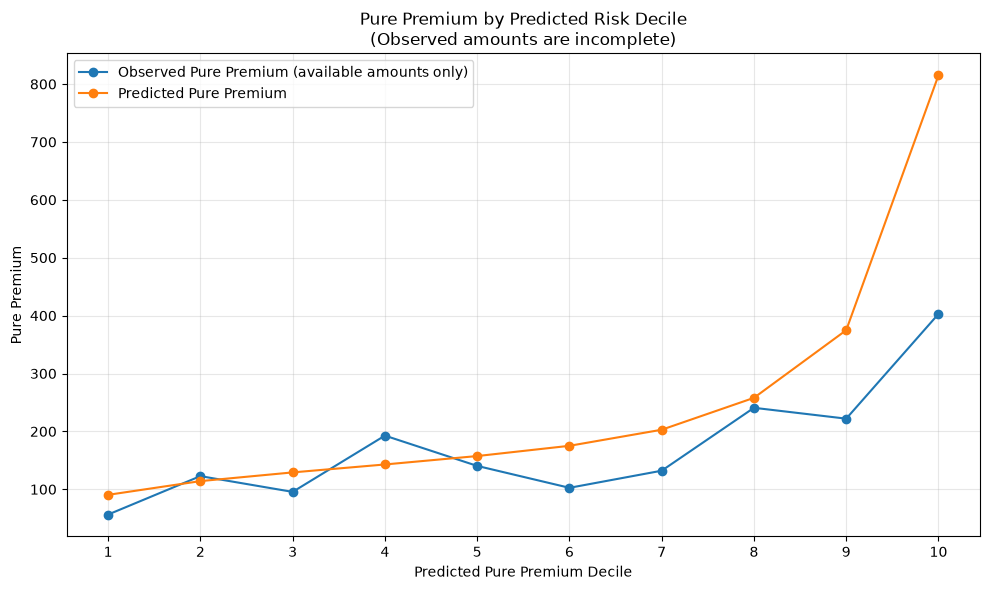

In [8]:
import matplotlib.pyplot as plt

pure_premium_calibration_plot = (
    pure_premium_calibration
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    pure_premium_calibration_plot["decile"],
    pure_premium_calibration_plot["observed_pure_premium"],
    marker="o",
    label="Observed Pure Premium (available amounts only)",
)

plt.plot(
    pure_premium_calibration_plot["decile"],
    pure_premium_calibration_plot["predicted_pure_premium"],
    marker="o",
    label="Predicted Pure Premium",
)

plt.xlabel("Predicted Pure Premium Decile")
plt.ylabel("Pure Premium")
plt.title(
    "Pure Premium by Predicted Risk Decile\n"
    "(Observed amounts are incomplete)"
)

plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Ergebnis:** Die Pure-Premium-Prognosen zeigen eine erkennbare
Risikodifferenzierung: Das höchste prognostizierte Dezil weist auch die
höchste beobachtete Pure Premium auf.

Die beobachteten Werte steigen jedoch nicht durchgehend monoton an, und
insbesondere in den oberen Risikodezilen überschätzt das Modell die
Schadenbelastung deutlich. Die Kalibrierung wird zusätzlich durch den
zunehmenden Anteil fehlender Schadenbeträge in den hohen Risikogruppen
eingeschränkt.

## Refit der finalen Modelle für die Inferenz

Nach Abschluss der Holdout-Bewertung werden die festgelegten
Modellspezifikationen auf den vollständig verfügbaren Trainingsdaten neu
geschätzt.

Dieser Refit dient ausschließlich der späteren Inferenz für das gesamte
Portfolio. Die zuvor ermittelten Holdout-Kennzahlen bleiben unverändert und
werden nicht durch den Full-Data-Refit ersetzt.

In [9]:
from sklearn.base import clone


# Full portfolio input
X_frequency_full = df[frequency_features].copy()

y_frequency_full = (
    df["ClaimNb"]
    / df["Exposure"]
)

w_frequency_full = df["Exposure"].copy()


print("=== Full Frequency Refit Setup ===")
print(f"Policies:              {len(X_frequency_full):,}")
print(f"Exposure:              {w_frequency_full.sum():,.2f}")
print(f"Claims:                {df['ClaimNb'].sum():,.0f}")
print(
    f"Portfolio frequency:   "
    f"{df['ClaimNb'].sum() / w_frequency_full.sum():.6f}"
)
print(
    f"Non-positive Exposure: "
    f"{(w_frequency_full <= 0).sum():,}"
)


frequency_model_full = clone(
    frequency_model
)

frequency_model_full.fit(
    X_frequency_full,
    y_frequency_full,
    model__sample_weight=w_frequency_full,
)

print("\nFull-data Frequency model fitted successfully.")
print(
    "Iterations used:",
    frequency_model_full.named_steps["model"].n_iter_,
)

=== Full Frequency Refit Setup ===
Policies:              678,013
Exposure:              358,360.11
Claims:                36,102
Portfolio frequency:   0.100742
Non-positive Exposure: 0

Full-data Frequency model fitted successfully.
Iterations used: 80


### Full-Data-Refit des Severity-Modells

Das finale Severity-Modell wird ausschließlich auf Policen mit vollständig
und konsistent beobachteter Schadenhöhe neu geschätzt.

Dabei werden dieselben Eligibility-Regeln wie bei der Holdout-Evaluation
verwendet. Der Refit dient ausschließlich der späteren Inferenz für das
gesamte Portfolio.

In [10]:
severity_full_mask = (
    (df["ClaimNb"] > 0)
    & df["total_claim_amount"].notna()
    & (df["total_claim_amount"] > 0)
    & (~df["missing_severity"])
    & (~df["claim_count_mismatch"])
)

severity_full = (
    df.loc[severity_full_mask]
    .copy()
)

X_severity_full = (
    severity_full[severity_features]
    .copy()
)

y_severity_full = (
    severity_full["total_claim_amount"]
    / severity_full["ClaimNb"]
)

w_severity_full = (
    severity_full["ClaimNb"]
    .copy()
)


print("=== Full Severity Refit Setup ===")
print(f"Eligible policies:        {len(severity_full):,}")
print(f"Claims represented:       {w_severity_full.sum():,.0f}")
print(
    f"Missing target values:    "
    f"{y_severity_full.isna().sum():,}"
)
print(
    f"Non-positive targets:     "
    f"{(y_severity_full <= 0).sum():,}"
)


severity_model_full = clone(
    severity_model
)

severity_model_full.fit(
    X_severity_full,
    y_severity_full,
    model__sample_weight=w_severity_full,
)

print("\nFull-data Severity model fitted successfully.")
print(
    "Iterations used:",
    severity_model_full.named_steps["model"].n_iter_,
)

=== Full Severity Refit Setup ===
Eligible policies:        24,943
Claims represented:       26,443
Missing target values:    0
Non-positive targets:     0

Full-data Severity model fitted successfully.
Iterations used: 11


### Inferenz für das gesamte Portfolio

Die auf den vollständigen verfügbaren Daten neu geschätzten Frequency- und
Severity-Modelle werden nun auf alle Policen angewendet.

Für jede Police werden die erwartete Schadenhäufigkeit, die erwartete
Schadenhöhe, die Pure Premium sowie exposure-korrigierte Erwartungswerte
berechnet.

In [11]:
portfolio_predictions = df[
    [
        "IDpol",
        "Exposure",
    ]
].copy()


# Full-data model predictions
portfolio_predictions["predicted_frequency"] = (
    frequency_model_full.predict(
        df[frequency_features]
    )
)

portfolio_predictions["predicted_severity"] = (
    severity_model_full.predict(
        df[severity_features]
    )
)


# Pure Premium
portfolio_predictions["predicted_pure_premium"] = (
    portfolio_predictions["predicted_frequency"]
    * portfolio_predictions["predicted_severity"]
)


# Exposure-correct expected values
portfolio_predictions["expected_claim_count"] = (
    portfolio_predictions["predicted_frequency"]
    * portfolio_predictions["Exposure"]
)

portfolio_predictions["expected_claim_amount"] = (
    portfolio_predictions["predicted_pure_premium"]
    * portfolio_predictions["Exposure"]
)


print("=== Full Portfolio Prediction Sanity Check ===")
print(f"Policies:                 {len(portfolio_predictions):,}")
print(
    f"Unique IDpol:             "
    f"{portfolio_predictions['IDpol'].nunique():,}"
)
print(
    f"Duplicate IDpol:          "
    f"{portfolio_predictions['IDpol'].duplicated().sum():,}"
)

prediction_columns = [
    "predicted_frequency",
    "predicted_severity",
    "predicted_pure_premium",
    "expected_claim_count",
    "expected_claim_amount",
]

print(
    f"Missing predictions:      "
    f"{portfolio_predictions[prediction_columns].isna().sum().sum():,}"
)

print(
    f"Infinite predictions:     "
    f"{np.isinf(
        portfolio_predictions[prediction_columns].to_numpy()
    ).sum():,}"
)

print(
    f"Non-positive frequency:   "
    f"{(portfolio_predictions['predicted_frequency'] <= 0).sum():,}"
)

print(
    f"Non-positive severity:    "
    f"{(portfolio_predictions['predicted_severity'] <= 0).sum():,}"
)

print(
    f"Non-positive Pure Premium:"
    f" {(portfolio_predictions['predicted_pure_premium'] <= 0).sum():,}"
)


print("\n=== Full Portfolio Expectations ===")
print(
    f"Actual claims:            "
    f"{df['ClaimNb'].sum():,.0f}"
)
print(
    f"Expected claims:          "
    f"{portfolio_predictions['expected_claim_count'].sum():,.2f}"
)
print(
    f"Expected claim amount:    "
    f"{portfolio_predictions['expected_claim_amount'].sum():,.2f}"
)

=== Full Portfolio Prediction Sanity Check ===
Policies:                 678,013
Unique IDpol:             678,013
Duplicate IDpol:          0
Missing predictions:      0
Infinite predictions:     0
Non-positive frequency:   0
Non-positive severity:    0
Non-positive Pure Premium: 0

=== Full Portfolio Expectations ===
Actual claims:            36,102
Expected claims:          36,096.16
Expected claim amount:    77,025,134.82


### Speicherung der Full-Data-Inferenzmodelle

Die auf den vollständig verfügbaren Daten neu geschätzten Modelle werden
separat von den Holdout-Modellartefakten gespeichert.

Die Full-Data-Modelle dienen ausschließlich der Inferenz für das gesamte
Portfolio und ersetzen nicht die zuvor evaluierten Holdout-Modelle.

In [18]:
import joblib


FREQUENCY_FULL_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_full_v2.joblib"
)

SEVERITY_FULL_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "severity_gamma_spline_scaled_full_v2.joblib"
)


joblib.dump(
    frequency_model_full,
    FREQUENCY_FULL_MODEL_PATH,
)

joblib.dump(
    severity_model_full,
    SEVERITY_FULL_MODEL_PATH,
)


print("=== Full-Data v2 Model Artifacts ===")

print(f"Frequency model: {FREQUENCY_FULL_MODEL_PATH}")
print(f"Exists:          {FREQUENCY_FULL_MODEL_PATH.exists()}")
print(
    f"Size:            "
    f"{FREQUENCY_FULL_MODEL_PATH.stat().st_size / 1024:.2f} KB"
)

print()

print(f"Severity model:  {SEVERITY_FULL_MODEL_PATH}")
print(f"Exists:          {SEVERITY_FULL_MODEL_PATH.exists()}")
print(
    f"Size:            "
    f"{SEVERITY_FULL_MODEL_PATH.stat().st_size / 1024:.2f} KB"
)

=== Full-Data v2 Model Artifacts ===
Frequency model: C:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\frequency_poisson_quantile_spline_full_v2.joblib
Exists:          True
Size:            8.31 KB

Severity model:  C:\Users\Mesut\Desktop\kfz-insurance-risk-platform\models\severity_gamma_spline_scaled_full_v2.joblib
Exists:          True
Size:            8.67 KB


### Validierung der Full-Data-v2-Modellartefakte

Die gespeicherten Frequency-v2- und Severity-v2-Full-Data-Modelle werden
erneut geladen und auf dem gesamten Portfolio ausgeführt.

Damit wird geprüft, ob die gespeicherten finalen Inferenzmodelle die zuvor
erzeugten Portfolio-Prognosen vollständig und reproduzierbar wiedergeben.

In [19]:
import joblib


# --------------------------------------------------
# Final v2 full-data artifact paths
# --------------------------------------------------

FREQUENCY_FULL_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "frequency_poisson_quantile_spline_full_v2.joblib"
)

SEVERITY_FULL_MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "severity_gamma_spline_scaled_full_v2.joblib"
)


# --------------------------------------------------
# Save final full-data models
# --------------------------------------------------

joblib.dump(
    frequency_model_full,
    FREQUENCY_FULL_MODEL_PATH,
)

joblib.dump(
    severity_model_full,
    SEVERITY_FULL_MODEL_PATH,
)


# --------------------------------------------------
# Reload saved artifacts
# --------------------------------------------------

loaded_frequency_full = joblib.load(
    FREQUENCY_FULL_MODEL_PATH
)

loaded_severity_full = joblib.load(
    SEVERITY_FULL_MODEL_PATH
)


# --------------------------------------------------
# Recreate full-portfolio predictions
# --------------------------------------------------

reloaded_frequency_pred = (
    loaded_frequency_full.predict(
        df[frequency_features]
    )
)

reloaded_severity_pred = (
    loaded_severity_full.predict(
        df[severity_features]
    )
)


# --------------------------------------------------
# Exact reproducibility checks
# --------------------------------------------------

frequency_identical = np.array_equal(
    portfolio_predictions[
        "predicted_frequency"
    ].to_numpy(),
    reloaded_frequency_pred,
)

severity_identical = np.array_equal(
    portfolio_predictions[
        "predicted_severity"
    ].to_numpy(),
    reloaded_severity_pred,
)


frequency_max_diff = np.max(
    np.abs(
        portfolio_predictions[
            "predicted_frequency"
        ].to_numpy()
        - reloaded_frequency_pred
    )
)

severity_max_diff = np.max(
    np.abs(
        portfolio_predictions[
            "predicted_severity"
        ].to_numpy()
        - reloaded_severity_pred
    )
)


print("=== Full-Data v2 Artifact Validation ===")

print(
    f"Frequency artifact exists: "
    f"{FREQUENCY_FULL_MODEL_PATH.exists()}"
)

print(
    f"Severity artifact exists:  "
    f"{SEVERITY_FULL_MODEL_PATH.exists()}"
)

print(f"Policies:                  {len(df):,}")

print("\nFrequency v2")
print(
    f"Predictions identical:     "
    f"{frequency_identical}"
)
print(
    f"Maximum abs. difference:   "
    f"{frequency_max_diff:.12f}"
)

print("\nSeverity v2")
print(
    f"Predictions identical:     "
    f"{severity_identical}"
)
print(
    f"Maximum abs. difference:   "
    f"{severity_max_diff:.12f}"
)

=== Full-Data v2 Artifact Validation ===
Frequency artifact exists: True
Severity artifact exists:  True
Policies:                  678,013

Frequency v2
Predictions identical:     True
Maximum abs. difference:   0.000000000000

Severity v2
Predictions identical:     True
Maximum abs. difference:   0.000000000000


**Ergebnis:** Die gespeicherten Full-Data-Modelle reproduzieren die zuvor
erzeugten Portfolio-Prognosen exakt.

Damit stehen reproduzierbare Frequency- und Severity-Inferenzmodelle für die
Scoring-Pipeline des gesamten Portfolios zur Verfügung.

## Vorbereitung der finalen Modellprognosen

Die finalen Portfolio-Prognosen werden für die Speicherung in PostgreSQL in
einer einheitlichen Prediction-Tabelle zusammengeführt.

Jeder Scoring-Lauf erhält eine eindeutige `prediction_run_id`. Zusätzlich
werden die verwendeten Modellversionen, die Exposure sowie der Zeitpunkt der
Prognose gespeichert.

In [20]:
from datetime import datetime, timezone
from uuid import uuid4


prediction_run_id = str(uuid4())
scored_at = datetime.now(timezone.utc)

frequency_model_version = "frequency_poisson_quantile_spline_full_v2"
severity_model_version = "severity_gamma_spline_scaled_full_v2"


model_predictions = pd.DataFrame({
    "idpol": portfolio_predictions["IDpol"].astype("int64"),

    "prediction_run_id": prediction_run_id,

    "frequency_model_version": frequency_model_version,
    "severity_model_version": severity_model_version,

    "predicted_frequency": (
        portfolio_predictions["predicted_frequency"]
    ),

    "predicted_severity": (
        portfolio_predictions["predicted_severity"]
    ),

    "predicted_pure_premium": (
        portfolio_predictions["predicted_pure_premium"]
    ),

    "exposure_used": (
        portfolio_predictions["Exposure"]
    ),

    "expected_claim_count": (
        portfolio_predictions["expected_claim_count"]
    ),

    "expected_claim_amount": (
        portfolio_predictions["expected_claim_amount"]
    ),

    "scored_at": scored_at,
})


print("=== model_predictions Setup ===")
print(f"Rows:                    {len(model_predictions):,}")
print(f"Columns:                 {model_predictions.shape[1]}")
print(f"Unique IDpol:            {model_predictions['idpol'].nunique():,}")
print(
    f"Duplicate IDpol:         "
    f"{model_predictions['idpol'].duplicated().sum():,}"
)
print(
    f"Missing values:          "
    f"{model_predictions.isna().sum().sum():,}"
)

print(
    f"Unique prediction runs:  "
    f"{model_predictions['prediction_run_id'].nunique():,}"
)

print(
    f"Non-positive frequency:  "
    f"{(model_predictions['predicted_frequency'] <= 0).sum():,}"
)

print(
    f"Non-positive severity:   "
    f"{(model_predictions['predicted_severity'] <= 0).sum():,}"
)

print(
    f"Non-positive Pure Prem.: "
    f"{(model_predictions['predicted_pure_premium'] <= 0).sum():,}"
)

print("\nPrediction Run ID:")
print(prediction_run_id)

print("\nModel versions:")
print(f"Frequency: {frequency_model_version}")
print(f"Severity:  {severity_model_version}")

display(model_predictions.head())

=== model_predictions Setup ===
Rows:                    678,013
Columns:                 11
Unique IDpol:            678,013
Duplicate IDpol:         0
Missing values:          0
Unique prediction runs:  1
Non-positive frequency:  0
Non-positive severity:   0
Non-positive Pure Prem.: 0

Prediction Run ID:
3e79d43b-d9e2-4edf-9056-be0827aa22f0

Model versions:
Frequency: frequency_poisson_quantile_spline_full_v2
Severity:  severity_gamma_spline_scaled_full_v2


,idpol,prediction_run_id,frequency_model_version,severity_model_version,predicted_frequency,predicted_severity,predicted_pure_premium,exposure_used,expected_claim_count,expected_claim_amount,scored_at
0,1,3e79d43b-d9e2-4edf-9056-be0827aa22f0,frequency_poisson_quantile_spline_full_v2,severity_gamma_spline_scaled_full_v2,0.328634,1824.448292,599.576065,0.10,0.032863,59.957607,2026-08-25 12:21:06.114380+00:00
1,3,3e79d43b-d9e2-4edf-9056-be0827aa22f0,frequency_poisson_quantile_spline_full_v2,severity_gamma_spline_scaled_full_v2,0.328634,1824.448292,599.576065,0.77,0.253048,461.673570,2026-08-25 12:21:06.114380+00:00
2,5,3e79d43b-d9e2-4edf-9056-be0827aa22f0,frequency_poisson_quantile_spline_full_v2,severity_gamma_spline_scaled_full_v2,0.091390,1874.041999,171.269572,0.75,0.068543,128.452179,2026-08-25 12:21:06.114380+00:00
3,10,3e79d43b-d9e2-4edf-9056-be0827aa22f0,frequency_poisson_quantile_spline_full_v2,severity_gamma_spline_scaled_full_v2,0.246669,1851.432834,456.690571,0.09,0.022200,41.102151,2026-08-25 12:21:06.114380+00:00
4,11,3e79d43b-d9e2-4edf-9056-be0827aa22f0,frequency_poisson_quantile_spline_full_v2,severity_gamma_spline_scaled_full_v2,0.246669,1851.432834,456.690571,0.84,0.207202,383.620080,2026-08-25 12:21:06.114380+00:00


**Ergebnis:** Für alle 678.013 Policen wurde ein vollständiger und
eindeutiger Prediction-Datensatz erzeugt.

Alle Prognosen sind gültig, enthalten keine fehlenden Werte und sind über
eine eindeutige `prediction_run_id` sowie die verwendeten Modellversionen
nachvollziehbar.

### Speicherung der finalen Portfolio-Prognosen

Die finalen Policy-Level-Prognosen werden als reproduzierbarer
Parquet-Output gespeichert.

Diese Datei bildet die Schnittstelle zwischen der Modellierungs- und der
PostgreSQL-Ladeschicht.

In [21]:
MODEL_PREDICTIONS_FILE = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "model_predictions.pq"
)

MODEL_PREDICTIONS_FILE.parent.mkdir(
    parents=True,
    exist_ok=True,
)

model_predictions.to_parquet(
    MODEL_PREDICTIONS_FILE,
    index=False,
)


reloaded_model_predictions = pd.read_parquet(
    MODEL_PREDICTIONS_FILE
)


print("=== Prediction Output Validation ===")
print(f"Saved file:             {MODEL_PREDICTIONS_FILE}")
print(f"Exists:                 {MODEL_PREDICTIONS_FILE.exists()}")
print(f"Rows:                   {len(reloaded_model_predictions):,}")
print(f"Columns:                {reloaded_model_predictions.shape[1]}")
print(
    f"Unique IDpol:           "
    f"{reloaded_model_predictions['idpol'].nunique():,}"
)
print(
    f"Unique prediction runs: "
    f"{reloaded_model_predictions['prediction_run_id'].nunique():,}"
)
print(
    f"Missing values:         "
    f"{reloaded_model_predictions.isna().sum().sum():,}"
)

=== Prediction Output Validation ===
Saved file:             C:\Users\Mesut\Desktop\kfz-insurance-risk-platform\data\output\model_predictions.pq
Exists:                 True
Rows:                   678,013
Columns:                11
Unique IDpol:           678,013
Unique prediction runs: 1
Missing values:         0


### PostgreSQL-Validierung der Modellprognosen

**Ergebnis:** Die finalen Portfolio-Prognosen wurden erfolgreich in
PostgreSQL gespeichert und anschließend direkt in der Datenbank validiert.

Alle 678.013 Policen sind eindeutig vorhanden. Die aggregierten erwarteten
Schadenanzahlen und Schadenbeträge stimmen exakt mit den zuvor in Python
berechneten Portfolio-Prognosen überein.

### Validierung der finalen Prediction-View

**Ergebnis:** Die finale Analyse-View wurde erfolgreich in PostgreSQL
erstellt und validiert.

Sie enthält eindeutig alle 678.013 Policen des aktuellen Scoring-Laufs.
Die aggregierten erwarteten Schadenanzahlen und Schadenbeträge stimmen exakt
mit der zugrunde liegenden Prediction-Tabelle und den Python-Ergebnissen überein.